<a href="https://colab.research.google.com/github/karolineb11/FUNDAMENTALS-OF-DATA-SCIENCE/blob/main/Exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

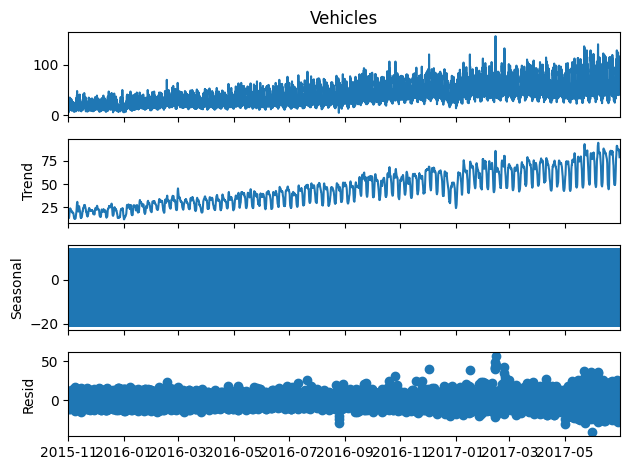

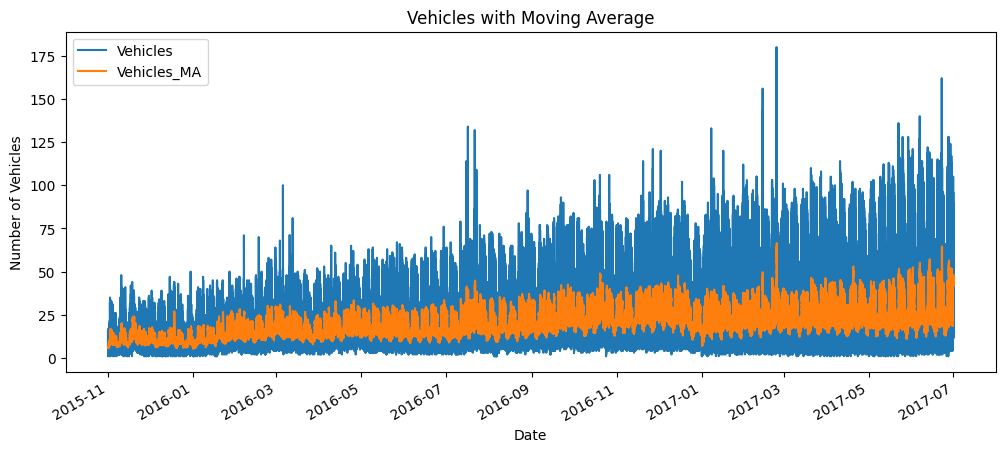

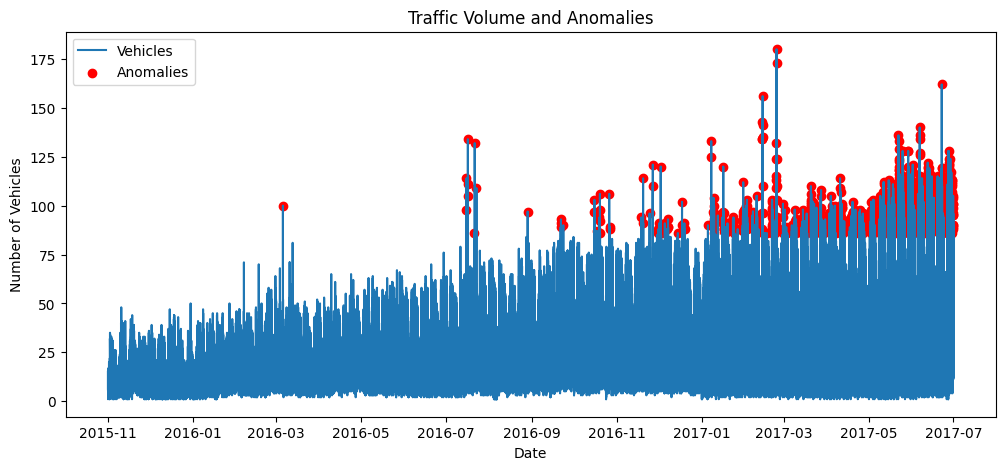

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset
data = pd.read_csv(
    '/content/traffic.csv',
    parse_dates=['DateTime']
)

# Set DateTime as index
data.set_index('DateTime', inplace=True)

# Sort by date
data.sort_index(inplace=True)

# Select Junction 1
junction_data = data[data['Junction'] == 1]['Vehicles']

# Time Series Decomposition
decomposition = seasonal_decompose(
    junction_data,
    model='additive',
    period=24
)

decomposition.plot()
plt.tight_layout()
plt.show()

# Moving Average
data['Vehicles_MA'] = data['Vehicles'].rolling(window=24).mean()

data[['Vehicles', 'Vehicles_MA']].plot(figsize=(12, 5))
plt.title('Vehicles with Moving Average')
plt.xlabel('Date')
plt.ylabel('Number of Vehicles')
plt.show()

# Anomaly Detection
data['Vehicles_Z'] = (
    (data['Vehicles'] - data['Vehicles'].mean())
    / data['Vehicles'].std()
)

anomalies = data[data['Vehicles_Z'].abs() > 3]

# Plot anomalies
plt.figure(figsize=(12, 5))

plt.plot(
    data.index,
    data['Vehicles'],
    label='Vehicles'
)

plt.scatter(
    anomalies.index,
    anomalies['Vehicles'],
    color='red',
    label='Anomalies'
)

plt.title('Traffic Volume and Anomalies')
plt.xlabel('Date')
plt.ylabel('Number of Vehicles')
plt.legend()
plt.show()
